**Series 4 · ML Fundamentals** ‣ [04-1 ML คืออะไร](./04-1-ml-introduction.ipynb) ・ [04-2 Train/Test Split & Overfitting](./04-2-train-test-split-and-overfitting.ipynb) ・ [04-3 Pipeline & Data Leakage](./04-3-pipeline-and-data-leakage.ipynb)

---

# ✂️ 04-2: Train/Test Split, Overfitting และ Cross-Validation

### 🎯 วัตถุประสงค์การเรียนรู้
1. แบ่งข้อมูลเป็น Train/Test ด้วย `train_test_split` ได้ถูกต้อง (รวม `stratify`)
2. อ่านคะแนน Train เทียบกับ Test แล้ววินิจฉัย **Overfitting / Underfitting** ได้
3. เข้าใจว่าทำไมต้องมี **Validation Set** และใช้ **Cross-Validation** แทนได้

## 1. ทำไมต้องแบ่งข้อมูล?

| ชุดข้อมูล | เปรียบเหมือน | ใช้ทำอะไร |
|---|---|---|
| **Train Set** (~70–80%) | แบบฝึกหัดที่มีเฉลย | ให้โมเดลเรียนรู้ (`fit`) |
| **Test Set** (~20–30%) | ข้อสอบจริงที่ไม่เคยเห็น | วัดผลครั้งสุดท้าย (`predict` + metric) |

> 🎯 เป้าหมายของ ML ไม่ใช่การจำข้อมูลเก่าได้ แต่คือ **ทำนายข้อมูลใหม่ได้แม่น (Generalization)**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 📌 ถ้าใช้ Google Colab: อัปโหลดไฟล์ CSV ที่แผง Files (ซ้ายมือ)
#    แล้วเปลี่ยน DATA_PATH เป็น "golf_dataset_weather_tropical_1year.csv"
DATA_PATH = "Data/golf_dataset_weather_tropical_1year.csv"
df = pd.read_csv(DATA_PATH)
print("ขนาดข้อมูล:", df.shape)

feature_cols = ['SunshineDuration', 'Temperature', 'Humidity',
                'WindDirection', 'WindSpeed', 'Pressure']
X = df[feature_cols]
y = df['TotalPlayer']

ขนาดข้อมูล: (365, 15)


## 2. `train_test_split`

| พารามิเตอร์ | ความหมาย | ค่าที่นิยม |
|---|---|---|
| `test_size` | สัดส่วนของ Test Set | `0.2` หรือ `0.3` |
| `random_state` | ล็อกการสุ่มให้ได้ผลเหมือนเดิมทุกครั้ง | `42` (ตัวเลขอะไรก็ได้) |
| `stratify` | รักษาสัดส่วนคลาสให้เท่ากันทั้ง Train/Test | `y` (**ใช้กับ Classification**) |
| `shuffle` | สุ่มลำดับก่อนแบ่ง | `True` (ค่าเริ่มต้น) |

> ⚠️ ลำดับผลลัพธ์ต้องจำให้แม่น: **`X_train, X_test, y_train, y_test`**

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("y_train:", y_train.shape, " y_test:", y_test.shape)

X_train: (292, 6)  X_test: (73, 6)
y_train: (292,)  y_test: (73,)


### 2.1 `stratify` สำหรับ Classification
ถ้าไม่ใส่ `stratify` สัดส่วนคลาสใน Train/Test อาจเพี้ยนไปจากข้อมูลจริง (ยิ่งข้อมูลน้อยหรือคลาสไม่สมดุลยิ่งเห็นชัด)

In [3]:
y_class = (df['TotalPlayer'] >= 60).astype(int)   # IsBusy จากบท 04-1

_, _, _, yc_test_no  = train_test_split(X, y_class, test_size=0.2, random_state=7)
_, _, _, yc_test_yes = train_test_split(X, y_class, test_size=0.2, random_state=7, stratify=y_class)

pd.DataFrame({
    'ข้อมูลทั้งหมด':      y_class.value_counts(normalize=True),
    'Test (ไม่ stratify)': yc_test_no.value_counts(normalize=True),
    'Test (stratify)':    yc_test_yes.value_counts(normalize=True),
}).round(3)

,ข้อมูลทั้งหมด,Test (ไม่ stratify),Test (stratify)
TotalPlayer,,,
1,0.559,0.534,0.562
0,0.441,0.466,0.438


## 3. วัดผลบน Train เทียบกับ Test

In [4]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)            # เรียนจาก Train เท่านั้น

print("R² Train:", round(lr.score(X_train, y_train), 3))
print("R² Test :", round(lr.score(X_test,  y_test),  3))

R² Train: 0.556
R² Test : 0.6


> ✅ คะแนน Train และ Test ใกล้เคียงกัน แปลว่าโมเดลไม่ได้แค่จำข้อมูล แต่ใช้กับข้อมูลใหม่ได้จริง

## 4. Overfitting vs Underfitting

| อาการ | Train Score | Test Score | ความหมาย | วิธีแก้ |
|---|---|---|---|---|
| **Underfitting** | ต่ำ | ต่ำ | โมเดลง่ายเกินไป เรียนรู้ไม่พอ | ใช้โมเดลซับซ้อนขึ้น / เพิ่ม Feature |
| **Good Fit** ✅ | สูง | สูง (ใกล้ Train) | สมดุล | — |
| **Overfitting** | สูงมาก | ต่ำกว่า Train ชัดเจน | **จำ** ข้อมูล รวมถึง noise | ลดความซับซ้อน / เพิ่มข้อมูล / Regularization |

### ทดลอง: ปรับความลึกของ Decision Tree
`max_depth` คือจำนวนชั้นของคำถาม ยิ่งลึก โมเดลยิ่งซับซ้อน

In [5]:
from sklearn.tree import DecisionTreeRegressor

results = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 15, None]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    results.append({
        'max_depth': 'None (ไม่จำกัด)' if depth is None else depth,
        'Train R²': round(tree.score(X_train, y_train), 3),
        'Test R²':  round(tree.score(X_test,  y_test),  3),
    })

results_df = pd.DataFrame(results)
results_df['Gap (Train-Test)'] = (results_df['Train R²'] - results_df['Test R²']).round(3)
results_df

,max_depth,Train R²,Test R²,Gap (Train-Test)
0,1,0.346,0.444,-0.098
1,2,0.502,0.449,0.053
2,3,0.599,0.519,0.080
3,4,0.679,0.548,0.131
4,5,0.771,0.517,0.254
5,6,0.823,0.477,0.346
6,8,0.929,0.378,0.551
7,10,0.988,0.352,0.636
8,15,1.000,0.334,0.666
9,None (ไม่จำกัด),1.000,0.334,0.666


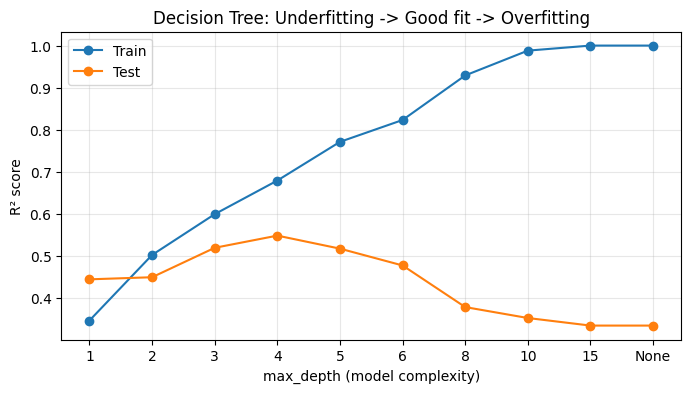

In [6]:
plot_df = results_df.copy()
plot_df['max_depth'] = plot_df['max_depth'].astype(str).str.replace(' (ไม่จำกัด)', '', regex=False)

plt.figure(figsize=(8, 4))
plt.plot(plot_df['max_depth'], plot_df['Train R²'], marker='o', label='Train')
plt.plot(plot_df['max_depth'], plot_df['Test R²'],  marker='o', label='Test')
plt.xlabel('max_depth (model complexity)')
plt.ylabel('R² score')
plt.title('Decision Tree: Underfitting -> Good fit -> Overfitting')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 🔍 อ่านกราฟ
- **ซ้ายสุด (depth 1)**: คะแนนต่ำทั้งคู่ → **Underfitting**
- **ช่วงกลาง (depth 3–4)**: Test สูงสุด → จุดที่ดีที่สุด
- **ขวาสุด (ไม่จำกัด)**: Train = 1.0 แต่ Test ตกลง → **Overfitting** (จำข้อสอบเก่าได้หมด แต่ทำข้อสอบใหม่ได้แย่)

## 5. ปัญหาใหม่: ถ้าเลือก `max_depth` จาก Test Set ก็โกงอีกแบบ!

ถ้าเราดูคะแนน Test แล้วเลือกค่าที่ดีที่สุด เท่ากับว่า **Test Set ถูกใช้ตัดสินใจไปแล้ว** จึงไม่ใช่ "ข้อสอบที่ไม่เคยเห็น" อีกต่อไป

```
ข้อมูลทั้งหมด
├── Train      → ใช้ fit
├── Validation → ใช้เลือกโมเดล / ปรับ hyperparameter
└── Test       → ใช้วัดผลครั้งสุดท้าย "ครั้งเดียว"
```

แต่ข้อมูลเรามีแค่ 365 แถว ถ้าแบ่ง 3 ส่วน แต่ละส่วนจะเล็กเกินไป → ใช้ **Cross-Validation** แทน

## 6. K-Fold Cross-Validation

แบ่ง Train Set เป็น K ส่วน (Fold) แล้วสลับให้แต่ละส่วนเป็น Validation รอบละ 1 ครั้ง

```
รอบ 1: [Val] [Trn] [Trn] [Trn] [Trn]  → score 1
รอบ 2: [Trn] [Val] [Trn] [Trn] [Trn]  → score 2
  ...
รอบ 5: [Trn] [Trn] [Trn] [Trn] [Val]  → score 5
                               คะแนนจริง = ค่าเฉลี่ย ± ส่วนเบี่ยงเบน
```

In [7]:
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(LinearRegression(), X_train, y_train, cv=kf, scoring='r2')

print("R² แต่ละ Fold:", scores.round(3))
print(f"ค่าเฉลี่ย: {scores.mean():.3f} ± {scores.std():.3f}")

R² แต่ละ Fold: [0.669 0.471 0.34  0.538 0.584]
ค่าเฉลี่ย: 0.521 ± 0.111


### ใช้ CV เลือก `max_depth` (โดยไม่แตะ Test Set)

In [8]:
cv_results = []
for depth in [1, 2, 3, 4, 5, 6, 8, None]:
    s = cross_val_score(DecisionTreeRegressor(max_depth=depth, random_state=42),
                        X_train, y_train, cv=kf, scoring='r2')
    cv_results.append({'max_depth': str(depth), 'CV R² mean': round(s.mean(), 3), 'CV R² std': round(s.std(), 3)})

cv_df = pd.DataFrame(cv_results)
best = cv_df.loc[cv_df['CV R² mean'].idxmax()]
print("max_depth ที่ดีที่สุดจาก CV:", best['max_depth'])
cv_df

max_depth ที่ดีที่สุดจาก CV: 3


,max_depth,CV R² mean,CV R² std
0,1,0.241,0.159
1,2,0.335,0.157
2,3,0.432,0.164
3,4,0.361,0.073
4,5,0.356,0.101
5,6,0.273,0.172
6,8,0.163,0.232
7,None,0.099,0.217


In [9]:
# ใช้ค่าที่ดีที่สุด เทรนบน Train ทั้งหมด แล้ววัดผลบน Test "ครั้งเดียว"
best_depth = None if best['max_depth'] == 'None' else int(best['max_depth'])
final_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42).fit(X_train, y_train)
print("R² Test (ครั้งสุดท้าย):", round(final_tree.score(X_test, y_test), 3))

R² Test (ครั้งสุดท้าย): 0.519


### StratifiedKFold สำหรับ Classification
ทำงานเหมือน KFold แต่รักษาสัดส่วนคลาสในทุก Fold (เหมือน `stratify` ใน `train_test_split`)

In [10]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
acc = cross_val_score(LogisticRegression(max_iter=1000), X, y_class, cv=skf, scoring='accuracy')
print("Accuracy แต่ละ Fold:", acc.round(3))
print(f"ค่าเฉลี่ย: {acc.mean():.3f} ± {acc.std():.3f}")

Accuracy แต่ละ Fold: [0.74  0.685 0.822 0.767 0.753]
ค่าเฉลี่ย: 0.753 ± 0.044


> 💡 ค่า `scoring` ที่ใช้บ่อย: Regression → `'r2'`, `'neg_mean_absolute_error'`, `'neg_root_mean_squared_error'`
> Classification → `'accuracy'`, `'f1'`, `'roc_auc'` (รายละเอียดใน Series 5–7)
> ⚠️ ค่า `neg_...` เป็นลบเพราะ sklearn ถือว่า "ยิ่งมากยิ่งดี" ให้ใส่ `-` ข้างหน้าเพื่ออ่านค่าจริง

---

## 7. สรุป

| แนวคิด | จำสั้นๆ |
|---|---|
| Train/Test Split | `X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)` |
| Classification | เพิ่ม `stratify=y` เสมอ |
| Overfitting | Train สูง แต่ Test ต่ำกว่ามาก |
| Underfitting | ต่ำทั้ง Train และ Test |
| เลือก hyperparameter | ใช้ Cross-Validation บน Train **ไม่ใช่** Test |
| Test Set | ใช้วัดผล **ครั้งสุดท้ายครั้งเดียว** |

## 📝 แบบฝึกหัด
ใช้ `KNeighborsRegressor` (จาก `sklearn.neighbors`) ลอง `n_neighbors` = 1, 3, 5, 10, 20, 50
แล้วหาว่าค่าไหนดีที่สุดด้วย Cross-Validation จากนั้นวัดผลบน Test
(คำใบ้: `n_neighbors=1` คือ Overfitting ส่วนค่าที่มากเกินไปคือ Underfitting)

In [11]:
# เฉลย
from sklearn.neighbors import KNeighborsRegressor

knn_results = []
for k in [1, 3, 5, 10, 20, 50]:
    knn = KNeighborsRegressor(n_neighbors=k)
    s = cross_val_score(knn, X_train, y_train, cv=kf, scoring='r2')
    train_r2 = knn.fit(X_train, y_train).score(X_train, y_train)
    knn_results.append({'n_neighbors': k, 'Train R²': round(train_r2, 3), 'CV R²': round(s.mean(), 3)})

knn_df = pd.DataFrame(knn_results)
print(knn_df)
best_k = int(knn_df.loc[knn_df['CV R²'].idxmax(), 'n_neighbors'])
print("\nk ที่ดีที่สุด:", best_k)
print("R² Test:", round(KNeighborsRegressor(n_neighbors=best_k).fit(X_train, y_train).score(X_test, y_test), 3))
# หมายเหตุ: KNN ใช้ระยะทาง ควร Scale ข้อมูลก่อน → ทำได้ง่ายด้วย Pipeline ในบท 04-3

   n_neighbors  Train R²  CV R²
0            1     1.000 -0.203
1            3     0.637  0.214
2            5     0.537  0.262
3           10     0.421  0.228
4           20     0.302  0.156
5           50     0.080 -0.007

k ที่ดีที่สุด: 5
R² Test: 0.425


---
⬅️ **บทก่อนหน้า:** [04-1 ML คืออะไร](./04-1-ml-introduction.ipynb) ・ ➡️ **บทถัดไป:** [04-3 Pipeline & Data Leakage](./04-3-pipeline-and-data-leakage.ipynb)